# 07 · PCA y K-NN de comandos de voz
**Trabajo Final · Inteligencia Artificial I · Ingeniería en Mecatrónica · UNCUYO · 2026**

**Cierre de desarrollo documentado: 23/10/2026, Argentina.**

Reconocer `identificar`, `reconocer` y `salir`. La implementación conserva las **160 características**
originales: PCA explora y visualiza; K-NN clasifica sin reducir dimensiones.
El notebook es una bitácora de lectura: **no graba, no entrena ni modifica particiones**.
Consulta una selección fija de evidencia Windows para que nuevas corridas locales no cambien este cierre.

Se cierra la versión de desarrollo. La evaluación con personas nuevas y la prueba final siguen pendientes.
No se afirma reconocimiento universal ni rechazo de cualquier palabra desconocida.

Fuentes: consigna `Trabajo Final 2026.pdf`, notebook 05, mapa de hablantes y tres paquetes de ejecución
compartidos por el autor. Instrucciones completas en `documentos/etapas/cierre_etapa07.md`.

> **Estado actual 27/10/2026:** k=5 uniforme con desempate por cercanía entre clases empatadas. Las evidencias de k=1 se conservan como referencia histórica. El apartado final contiene la comparación y métricas de la versión actual; no se atribuyen a k=5 las pruebas históricas de micrófono.


In [8]:
from pathlib import Path
import csv
import hashlib
import json
from IPython.display import display, Markdown, Image

RAIZ = Path.cwd().resolve()
if not (RAIZ / "documentos/evidencias/07_comandos_voz").is_dir():
    RAIZ = RAIZ.parent
EVIDENCIA = RAIZ / "documentos/evidencias/07_comandos_voz"
assert EVIDENCIA.is_dir(), "Abrir desde la raíz del repositorio o desde notebooks/."

def leer(rel):
    return json.loads((EVIDENCIA / rel).read_text(encoding="utf-8-sig"))

def filas(rel):
    with (EVIDENCIA / rel).open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

def mostrar_tabla(registros):
    if not registros:
        display(Markdown("Sin registros."))
        return
    columnas = list(registros[0])
    texto = "| " + " | ".join(columnas) + " |\n| " + " | ".join(["---"]*len(columnas)) + " |\n"
    texto += "\n".join("| " + " | ".join(str(r[k]).replace("|", "/") for k in columnas) + " |" for r in registros)
    display(Markdown(texto))

integridad = leer("integridad.json")
for nombre, esperado in integridad.items():
    p = EVIDENCIA / nombre
    assert p.is_file(), f"Falta evidencia: {nombre}"
    assert hashlib.sha256(p.read_bytes()).hexdigest() == esperado, f"Evidencia modificada: {nombre}"
resumen = leer("01_loso/resumen.json")
print("Evidencia fija:", EVIDENCIA.relative_to(RAIZ))
print("Archivos verificados:", len(integridad))
print("Ajuste original:", resumen["plataforma"], "Python", resumen["python"])
print("Dependencias del ajuste:", resumen["dependencias"])
print("Esta lectura no genera un modelo nuevo.")

Evidencia fija: documentos\resultados_etapa07
Archivos verificados: 64
Ajuste original: Windows-11-10.0.26200-SP0 Python 3.14.0
Dependencias del ajuste: {'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}
Esta lectura no genera un modelo nuevo.


## 1. Datos, revisiones y separación de voces

El corte cuenta con 180 originales: 179 conservados y uno excluido por revisión previa de ruido,
`H006_S001_salir_0005`. Las cantidades de las tablas se leen de los archivos y describen esta ejecución.
No se eliminó ninguna muestra válida por empeorar los gráficos o las métricas.

El mapa `config/particiones_audio_v1.json` destina H001–H006 a entrenamiento/desarrollo.
El catálogo histórico puede mantener `sin_asignar`; la capa explícita del mapa resuelve su uso.
No existen todavía voces humanas nuevas asignadas a validación externa ni a prueba final.
Las etiquetas, identidad del hablante, sesión e IDs no se incorporan a las 160 columnas.

No es una tarea de identificar personas: la clase que queremos predecir es **la palabra**.

In [9]:
print("Dimensión:", resumen["dimension"])
print("Columnas eliminadas:", resumen["columnas_eliminadas"])
print("Columnas constantes:", resumen["constantes_train"])
print("Voces en entrenamiento:", resumen["hablantes_entrenamiento"])
print("Particiones usadas:", resumen["cantidades"])
assert resumen["dimension"] == 160 and not resumen["columnas_eliminadas"]
assert resumen["prueba_evaluada"] is False
mostrar_tabla(filas("01_loso/cantidades.csv"))

Dimensión: 160
Columnas eliminadas: []
Columnas constantes: []
Voces en entrenamiento: ['H001', 'H002', 'H003', 'H004', 'H005', 'H006']
Particiones usadas: {'entrenamiento': 179}


| particion_analisis | hablante | comando | n |
| --- | --- | --- | --- |
| entrenamiento | H001 | identificar | 10 |
| entrenamiento | H001 | reconocer | 10 |
| entrenamiento | H001 | salir | 10 |
| entrenamiento | H002 | identificar | 10 |
| entrenamiento | H002 | reconocer | 10 |
| entrenamiento | H002 | salir | 10 |
| entrenamiento | H003 | identificar | 10 |
| entrenamiento | H003 | reconocer | 10 |
| entrenamiento | H003 | salir | 10 |
| entrenamiento | H004 | identificar | 10 |
| entrenamiento | H004 | reconocer | 10 |
| entrenamiento | H004 | salir | 10 |
| entrenamiento | H005 | identificar | 10 |
| entrenamiento | H005 | reconocer | 10 |
| entrenamiento | H005 | salir | 10 |
| entrenamiento | H006 | identificar | 10 |
| entrenamiento | H006 | reconocer | 10 |
| entrenamiento | H006 | salir | 9 |

## 2. Estandarización y PCA: qué representan los gráficos

Cada columna se estandariza con entrenamiento:

$$\boxed{z_j=\frac{x_j-\mu_{j,train}}{\sigma_{j,train}}}$$

Se usa desviación `ddof=0`. Una columna constante conservaría su posición con escala 1 para evitar
dividir por cero; no hay columnas constantes en este corte. Los nombres, orden, medias y escalas se guardan.

PCA construye combinaciones de características que concentran variación, **sin utilizar las etiquetas**.
Cada punto es una grabación. Ambas vistas usan las mismas coordenadas: cambia solamente si el color
indica palabra o hablante. Las componentes no son columnas originales seleccionadas.

La varianza acumulada mide información geométrica representada, no exactitud de clasificación.
El solapamiento en PC1–PC2 no demuestra que los comandos sean inseparables en el espacio completo.
No se exige que este dibujo se parezca al de huellas: son datos y representaciones diferentes.
**PCA se usa solo para visualizar; K-NN recibe las 160 columnas estandarizadas.**

PC1+PC2: 27.75 % de varianza
Componentes para alcanzar 95 %: 52


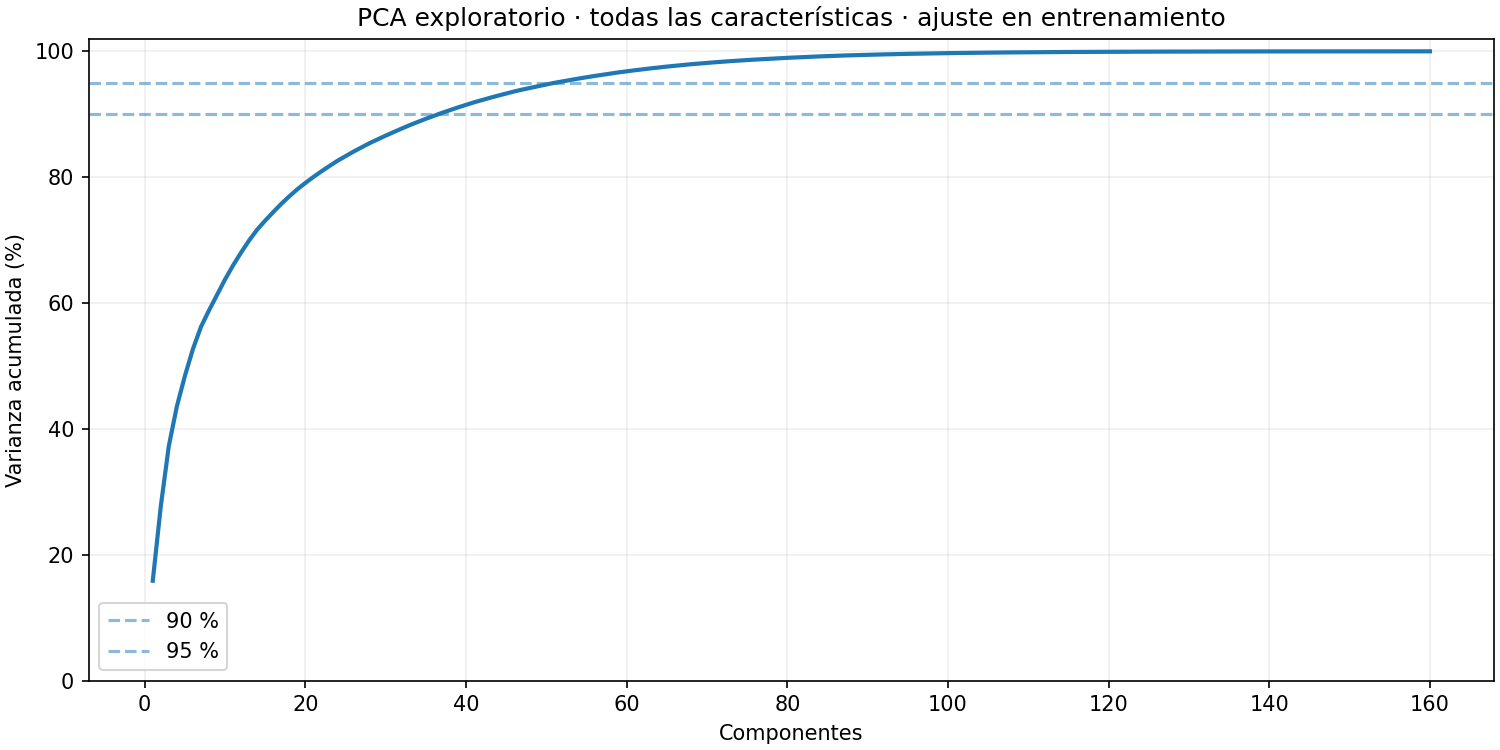

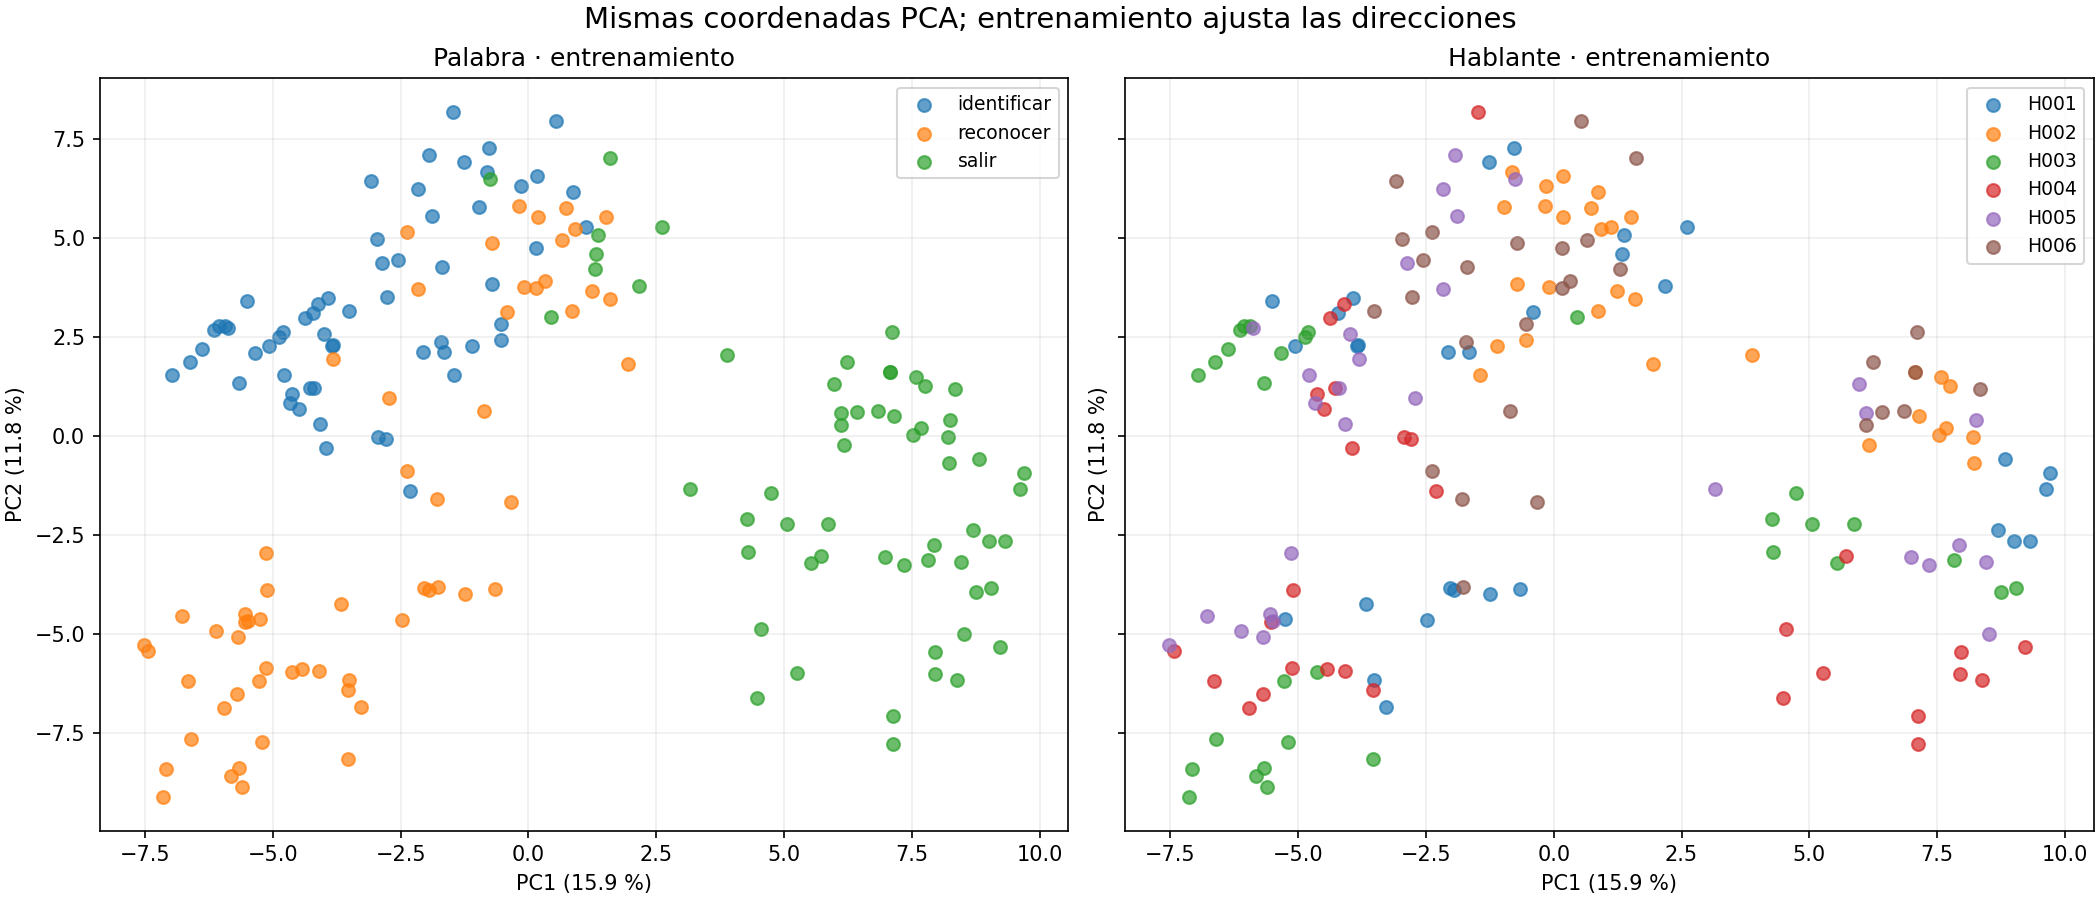

In [10]:
print(f"PC1+PC2: {resumen['pc1_pc2_porcentaje']:.2f} % de varianza")
print("Componentes para alcanzar 95 %:", resumen["componentes_95"])
assert resumen["pca_utilizado_para_clasificar"] is False
display(Image(filename=str(EVIDENCIA / "01_loso/varianza_acumulada.png"), width=1000))
display(Image(filename=str(EVIDENCIA / "01_loso/pca_palabras_hablantes.png"), width=1300))

## 3. Referencia histórica k=1: K-NN: ejemplos cercanos y evaluación LOSO

K-NN guarda ejemplos de entrenamiento con sus palabras. Para una nueva consulta busca vecinos
según la distancia euclidiana en las columnas estandarizadas:

$$\boxed{d(\mathbf z,\mathbf v)=\sqrt{\sum_{j=1}^{160}(z_j-v_j)^2}}$$

`k` significa cantidad de **vecinos**, no cantidad de palabras ni grupos. No hay centroides,
inicialización aleatoria ni K-means de audio. Con k=1 gana la palabra del ejemplo más cercano.
Con más vecinos se vota: uniforme cuenta ejemplos y por distancia da más peso a los cercanos.

Se compararon ocho alternativas: k=1,3,5,7 y dos tipos de voto. **LOSO** deja fuera un hablante
por vez, ajusta con las otras cinco voces y evalúa con la retenida. En cada pliegue se ajusta
su propio escalador exclusivamente con las voces de ajuste; el PCA global no interviene.

Se elige el mayor recall macro medio por hablante: igual peso a cada comando y después a cada voz.
En empate dentro de 1e-12 se prefiere voto uniforme y luego menor k. Se conserva k=5 uniforme
como referencia fija. Un k impar no garantiza ausencia de empate con tres clases; los empates
siguen las reglas de scikit-learn. Se mantiene el orden de ejemplos para reproducibilidad.

**La misma CV se usa para selección y para informar estos resultados de desarrollo**: el porcentaje
de la alternativa elegida puede ser optimista. No se presenta como prueba independiente.

| k | votos | hablantes | recall_macro_medio | exactitud_media | recall_macro_peor_hablante |
| --- | --- | --- | --- | --- | --- |
| 1 | uniform | 6 | 0.9438271604938272 | 0.9436781609195402 | 0.8629629629629628 |
| 1 | distance | 6 | 0.9438271604938272 | 0.9436781609195402 | 0.8629629629629628 |
| 3 | uniform | 6 | 0.9327160493827161 | 0.9325670498084291 | 0.8629629629629628 |
| 3 | distance | 6 | 0.9327160493827161 | 0.9325670498084291 | 0.8629629629629628 |
| 5 | uniform | 6 | 0.9216049382716051 | 0.921264367816092 | 0.8296296296296296 |
| 5 | distance | 6 | 0.9271604938271606 | 0.9268199233716475 | 0.8296296296296296 |
| 7 | uniform | 6 | 0.9098765432098767 | 0.9101532567049809 | 0.825925925925926 |
| 7 | distance | 6 | 0.9209876543209877 | 0.921264367816092 | 0.825925925925926 |

| modelo | n | exactitud |
| --- | --- | --- |
| Referencia k=5 uniforme | 179 | 92.18 % |
| Selección k=1 uniforme | 179 | 94.41 % |

Elegido: {'k': 1, 'votos': 'uniform'}


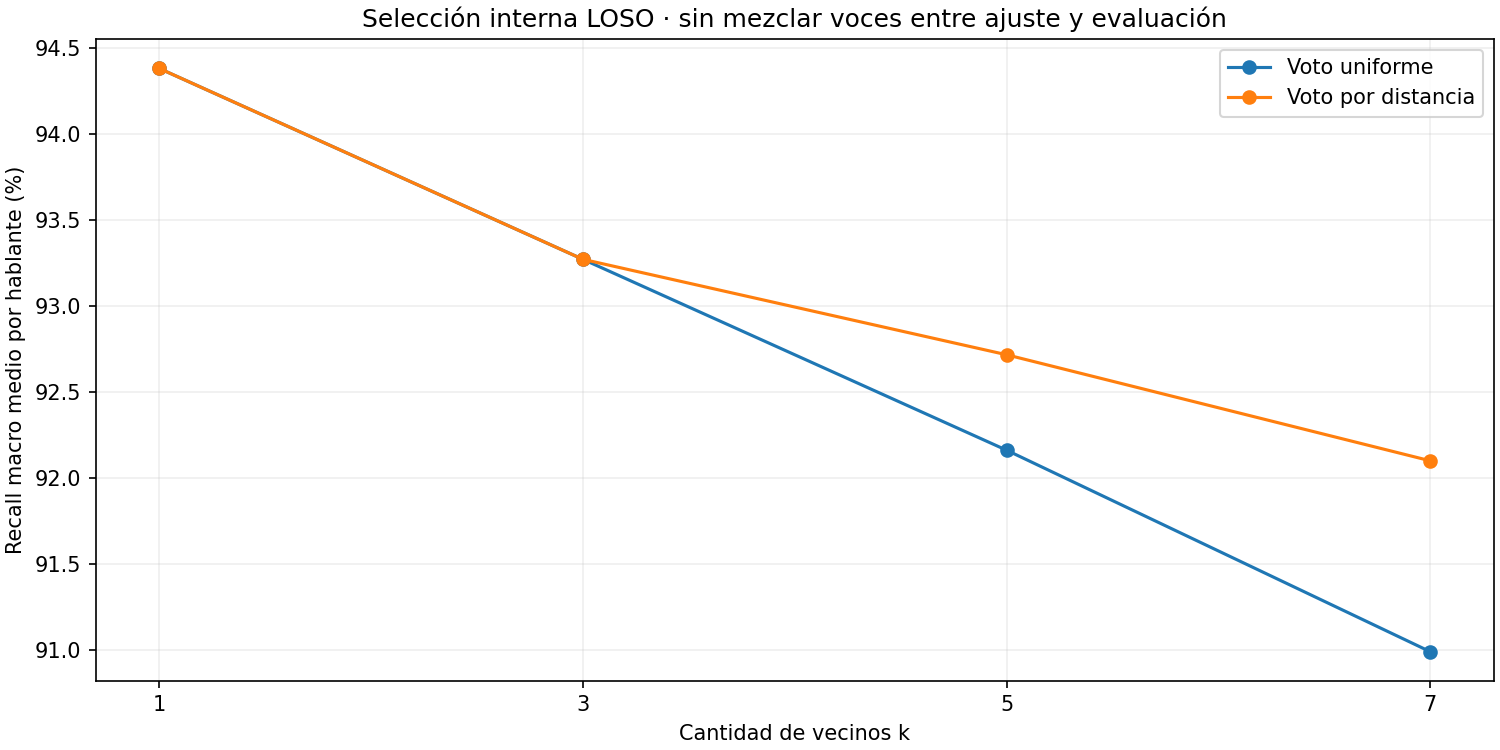

In [11]:
mostrar_tabla(filas("01_loso/comparacion_cv.csv"))
mostrar_tabla([dict(modelo=nombre, n=resumen[clave]["n"],
    exactitud=f"{100*resumen[clave]['exactitud']:.2f} %")
    for nombre, clave in [("Referencia k=5 uniforme", "cv_referencia"), ("Selección k=1 uniforme", "cv_seleccion")]])
print("Elegido:", resumen["parametros"])
display(Image(filename=str(EVIDENCIA / "01_loso/comparacion_k.png"), width=1000))

## 4. Errores históricos k=1 de la evaluación interna

Las filas de la matriz representan palabras reales y las columnas palabras predichas.
La diagonal cuenta aciertos. Las predicciones se hicieron dejando fuera la voz de cada muestra.

Identificar tuvo 60/60 ejemplos propios reconocidos, pero recibió siete ejemplos de otras palabras:
recall 100 % no significa precisión 100 %. Los diez errores no se borraron.
H006 y H001 concentran más fallos; las tablas orientan una investigación, sin demostrar la causa.
Ruido, pronunciación, captura y representación son hipótesis que requieren revisar los audios.

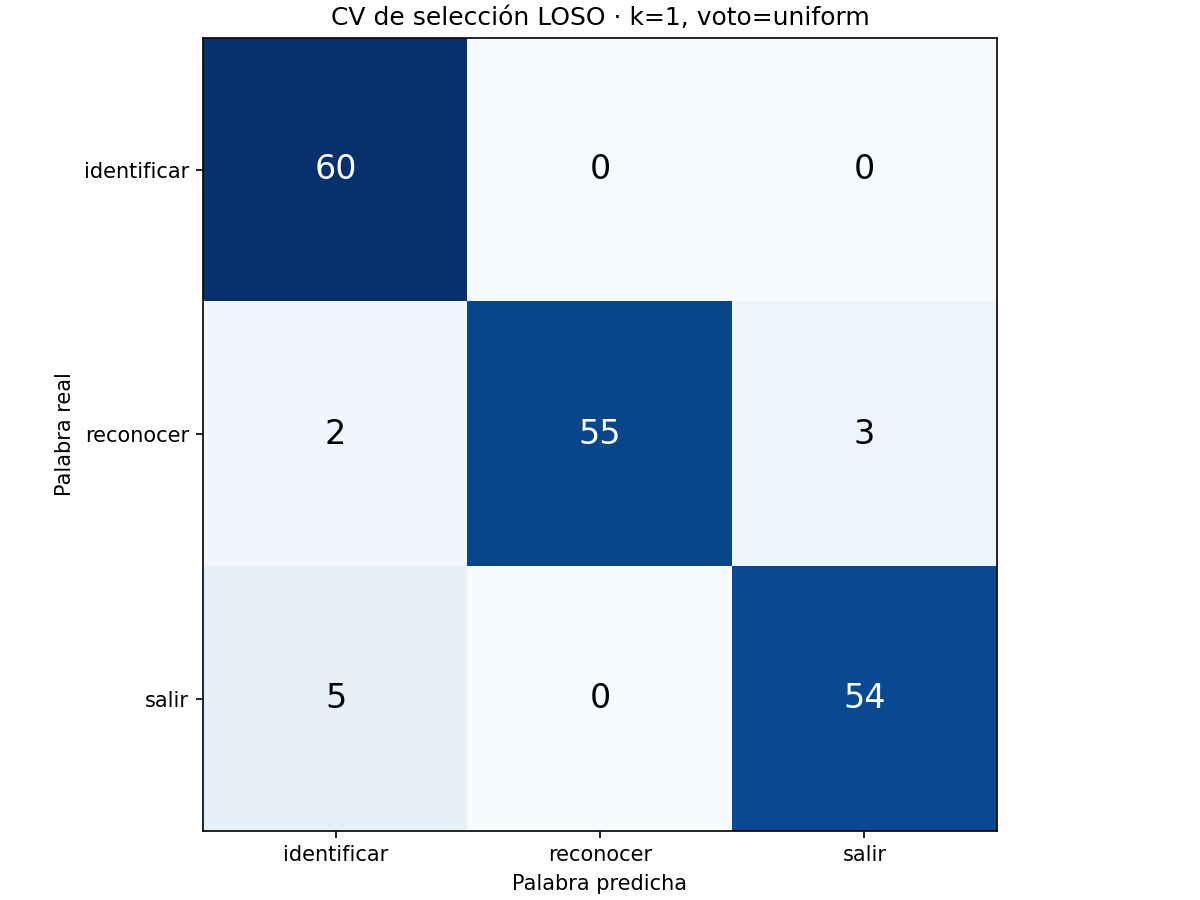

| comando | precision | recall | f1 | n |
| --- | --- | --- | --- | --- |
| identificar | 0.8955223880597015 | 1.0 | 0.9448818897637795 | 60 |
| reconocer | 1.0 | 0.9166666666666666 | 0.9565217391304348 | 60 |
| salir | 0.9473684210526315 | 0.9152542372881356 | 0.9310344827586207 | 59 |

| hablante | n | exactitud | recall_macro | f1_macro |
| --- | --- | --- | --- | --- |
| H001 | 30 | 0.9 | 0.9 | 0.8976982097186701 |
| H002 | 30 | 0.9666666666666667 | 0.9666666666666667 | 0.9665831244778613 |
| H003 | 30 | 1.0 | 1.0 | 1.0 |
| H004 | 30 | 1.0 | 1.0 | 1.0 |
| H005 | 30 | 0.9333333333333333 | 0.9333333333333332 | 0.934609250398724 |
| H006 | 29 | 0.8620689655172413 | 0.8629629629629628 | 0.8586367880485527 |

Errores conservados: 10


| k | votos | muestra | hablante | real | prediccion |
| --- | --- | --- | --- | --- | --- |
| 1 | uniform | H001_S001_salir_0002 | H001 | salir | identificar |
| 1 | uniform | H001_S001_salir_0005 | H001 | salir | identificar |
| 1 | uniform | H001_S001_salir_0007 | H001 | salir | identificar |
| 1 | uniform | H002_S001_reconocer_0010 | H002 | reconocer | identificar |
| 1 | uniform | H005_S001_reconocer_0008 | H005 | reconocer | identificar |
| 1 | uniform | H005_S001_salir_0002 | H005 | salir | identificar |
| 1 | uniform | H006_S001_reconocer_0005 | H006 | reconocer | salir |
| 1 | uniform | H006_S001_reconocer_0007 | H006 | reconocer | salir |
| 1 | uniform | H006_S001_reconocer_0010 | H006 | reconocer | salir |
| 1 | uniform | H006_S001_salir_0009 | H006 | salir | identificar |

In [12]:
display(Image(filename=str(EVIDENCIA / "01_loso/matriz_cv_seleccion.png"), width=800))
mostrar_tabla(filas("01_loso/metricas_comando_cv_seleccion.csv"))
mostrar_tabla(filas("01_loso/metricas_hablante_cv_seleccion.csv"))
errores = filas("01_loso/errores_cv_seleccion.csv")
print("Errores conservados:", len(errores))
mostrar_tabla(errores)
assert len(errores) == resumen["cv_seleccion"]["n"] - round(resumen["cv_seleccion"]["n"]*resumen["cv_seleccion"]["exactitud"])

## 5. Herramientas y modelo histórico

Después de seleccionar parámetros se ajustó un escalador con todo entrenamiento y se guardaron los
ejemplos etiquetados, k/votos, nombres, orden y PCA. Una consulta usa esos parámetros sin recalcularlos.

| Programa | Qué hace |
|---|---|
| `knn_audio.py` | Compara parámetros y crea otra corrida de entrenamiento |
| `probar_knn_audio.py` | Graba o lee un WAV y consulta un modelo guardado |
| `diagnosticar_knn_audio.py` | Reproduce LOSO e inspecciona los errores anteriores |

La palabra esperada elegida en el menú sirve para comparar al final; **no orienta la predicción**.
El ID H001/H007 solo registra la sesión; no filtra los ejemplos. Se compara con todo entrenamiento.
Se muestran hasta cinco vecinos de diagnóstico aunque el modelo decide con k=1.
No se agregan consultas al entrenamiento ni se elige otro k para cada grabación.

El diagnóstico informado por el autor reprodujo `169/179 | errores: 10` en Windows.
Son los mismos errores del dataset anterior, no errores de la nueva sesión. Sus ajustes por pliegue
son temporales y no sobrescriben el modelo guardado.

## 6. Prueba real con micrófono: voz conocida

Sesión UTC `20261023T115814_373387Z`, Windows/Python 3.14.0; H001, ya presente en entrenamiento.
Se grabaron **tomas nuevas** con el modelo fijo. Por eso no son los mismos audios del dataset,
pero tampoco una evaluación con una persona desconocida.

Se reconocieron 5/5 identificar, 5/5 reconocer y 5/5 salir. Además hubo una palabra desconocida
clasificada como salir y un silencio sin vector. El 100 % corresponde a los 15 comandos conocidos,
no a 17 aciertos de un sistema con rechazo. El silencio fue detenido por actividad insuficiente
en preprocesamiento; K-NN no llegó a recibirlo.

In [13]:
contexto = leer("02_microfono_conocida/contexto.json")
practica = leer("02_microfono_conocida/resumen_prueba.json")
intentos = filas("02_microfono_conocida/intentos.csv")
assert contexto["modelo_sha256"] == resumen["archivos_sha256"]["modelo.npz"]
print("Resumen original de la sesión:", practica)
mostrar_tabla(intentos)
assert sum(int(f["acierto"]) for f in intentos if f["acierto"] != "") == practica["aciertos"]
print("Interpretación: funcionamiento práctico con voz conocida; no generalización a personas nuevas.")

Resumen original de la sesión: {'intentos': 17, 'comandos_intentados': 15, 'aciertos': 15, 'sin_vector': 1, 'exactitud_por_intento': 1.0, 'nota': 'Prueba práctica de desarrollo; sin_vector cuenta como fallo en comandos conocidos. No es prueba final independiente.'}


| muestra | esperada | prediccion | estado | acierto | avisos |
| --- | --- | --- | --- | --- | --- |
| toma_001 | identificar | identificar | prediccion | 1 |  |
| toma_002 | identificar | identificar | prediccion_con_avisos | 1 | picos_cercanos_al_limite_original |
| toma_003 | identificar | identificar | prediccion | 1 |  |
| toma_004 | identificar | identificar | prediccion | 1 |  |
| toma_005 | identificar | identificar | prediccion | 1 |  |
| toma_006 | reconocer | reconocer | prediccion | 1 |  |
| toma_007 | reconocer | reconocer | prediccion | 1 |  |
| toma_008 | reconocer | reconocer | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_009 | reconocer | reconocer | prediccion | 1 |  |
| toma_010 | reconocer | reconocer | prediccion | 1 |  |
| toma_011 | salir | salir | prediccion | 1 |  |
| toma_012 | salir | salir | prediccion | 1 |  |
| toma_013 | salir | salir | prediccion | 1 |  |
| toma_014 | salir | salir | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_015 | salir | salir | prediccion | 1 |  |
| toma_016 | otra | salir | prediccion |  |  |
| toma_017 | silencio | SIN_VECTOR | sin_vector_revisar |  | sin_actividad_suficiente_segun_energia |

Interpretación: funcionamiento práctico con voz conocida; no generalización a personas nuevas.


## 7. Ensayo adicional: voces sintéticas por celular

Sesión UTC `20261023T121951_936996Z`. El autor aclaró que eran cuatro voces sintéticas
reproducidas desde un celular. Todas se anotaron como H007: no se puede calcular acierto por voz
ni atribuir las diferencias solamente al acento. Se combinan síntesis, parlante, ambiente y micrófono.
Es una exploración secundaria, no validación con personas reales.

Se conserva el resumen automático de **14/17 intentos** (82,35 %). El autor aclaró que en toma_001
no inició a tiempo la reproducción: se documenta como incidente de ejecución, sin borrar la fila.
En los **16 audios efectivamente reproducidos**, el análisis complementario da **14/16** (87,5 %).
Los errores de clasificación son toma_014 y toma_015: salir se interpretó como reconocer.
Esta distinción no cambia el resumen original ni demuestra rechazo de entradas desconocidas.

In [14]:
sint = leer("03_sinteticas/resumen_prueba.json")
anotacion = leer("03_sinteticas/observaciones_autor.json")
contexto_sint = leer("03_sinteticas/contexto.json")
assert contexto_sint["modelo_sha256"] == contexto["modelo_sha256"]
print("Resumen automático intacto:", sint)
print("Aclaración del autor:", anotacion["toma_001"])
print("Análisis complementario:", anotacion["analisis_complementario"])
mostrar_tabla(filas("03_sinteticas/intentos.csv"))

Resumen automático intacto: {'intentos': 17, 'comandos_intentados': 17, 'aciertos': 14, 'sin_vector': 1, 'exactitud_por_intento': 0.8235294117647058, 'nota': 'Prueba práctica de desarrollo; sin_vector cuenta como fallo en comandos conocidos. No es prueba final independiente.'}
Aclaración del autor: La reproducción no se inició a tiempo. Incidente de ejecución, no confusión de K-NN.
Análisis complementario: {'audios_efectivamente_reproducidos': 16, 'aciertos': 14, 'proporcion': 0.875, 'errores_clasificacion': ['toma_014', 'toma_015']}


| muestra | esperada | prediccion | estado | acierto | avisos |
| --- | --- | --- | --- | --- | --- |
| toma_001 | identificar | SIN_VECTOR | sin_vector_revisar | 0 | sin_actividad_suficiente_segun_energia |
| toma_002 | identificar | identificar | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_003 | identificar | identificar | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_004 | identificar | identificar | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_005 | identificar | identificar | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_006 | reconocer | reconocer | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_007 | reconocer | reconocer | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_008 | reconocer | reconocer | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_009 | reconocer | reconocer | prediccion | 1 |  |
| toma_010 | reconocer | reconocer | prediccion | 1 |  |
| toma_011 | reconocer | reconocer | prediccion | 1 |  |
| toma_012 | reconocer | reconocer | prediccion_con_avisos | 1 | picos_cercanos_al_limite_original |
| toma_013 | salir | salir | prediccion | 1 |  |
| toma_014 | salir | reconocer | prediccion_con_avisos | 0 | amplificacion_limitada |
| toma_015 | salir | reconocer | prediccion | 0 |  |
| toma_016 | salir | salir | prediccion_con_avisos | 1 | amplificacion_limitada |
| toma_017 | salir | salir | prediccion_con_avisos | 1 | amplificacion_limitada |

## 8. Verificaciones y alcance del cierre

Los resultados de entrenamiento y las sesiones prácticas fueron ejecutados por el autor en Windows.
Se recuperaron sus tres ZIP, se verificaron hashes y coherencia de predicciones y cantidades, y se
conservó la identidad del modelo entre sesiones. Los CSV y resúmenes originales no se reescribieron.
`contexto.json` solo omite la ruta personal absoluta; la procedencia queda registrada.

En este cierre se ejecutaron en Linux las celdas de **lectura y comprobación** del notebook.
No se entrenó otro modelo, se capturó audio ni se hizo una escucha auditiva nueva.
Las pruebas del software aprobadas en avances anteriores son antecedentes, no nuevas mediciones
de robustez de este cierre. La documentación completa distingue ambos entornos.

La evidencia seleccionada no incluye WAV nuevos ni el modelo NPZ. Conservar las carpetas locales
completas del modelo, extracción y sesiones. El notebook sí puede consultarse con una clonación del
repositorio sin regenerar matrices. Publicar resultados seleccionados no exige publicar voces nuevas.

## 9. Conclusiones del cierre histórico

Se implementó una referencia reproducible con las 160 características y se conservan sus errores.
La CV de selección obtuvo 169/179; la prueba práctica de H001 obtuvo 15/15 comandos conocidos.
Estas cifras corresponden a escenarios distintos y no se combinan en una sola exactitud.
El ensayo sintético se registra como exploración adicional.

**Se cierra la implementación y documentación de desarrollo; no se declara terminada la evaluación final.**
Quedan pendientes validación con personas nuevas, prueba final reservada, integración del agente
y rechazo calibrado de palabras desconocidas si lo requiere su uso. No se sigue ajustando para
forzar cero errores ni se eliminan muestras válidas.

Cuando haya participantes: asignar un ID distinto a cada persona, usar el mismo modelo y registrar
una tanda equilibrada por palabra conservando todos los intentos. Si sus resultados sirven para
mejorar el sistema, esas voces son validación/desarrollo; reservar otras para prueba final.
No hay necesidad de rehacer el extractor antes de contar con esa evidencia.

Los comandos de reproducción, las condiciones y los commits están en `documentos/etapas/cierre_etapa07.md`
y en la guía de instalación del cierre. La bitácora 06 de huellas permanece sin cambios.

## Actualización: versión actual k=5 y desempate explícito

Por recomendación docente se restringió la selección a **k=5 y k=7**, buscando menor dependencia de un único vecino. Se eligió mayor **precisión macro media por hablante**, calculada en las mismas seis vueltas LOSO y con escalador propio por vuelta. Se define precisión de una palabra como aciertos de esa palabra / veces que fue predicha. Primero se promedian las tres palabras y después las seis voces, con igual peso. Si una palabra no se predice, su precisión se informa como cero. Empate de selección a 1e-12: menor k.

Con la regla nueva, k=5 obtuvo **94,51 %** de precisión macro media y **92,72 %** de recall macro medio; k=7 obtuvo **94,01 %** y **92,10 %**. Ganó **k=5**. Exactitud agregada de k=5: **166/179 = 92,74 %**. Las métricas macro por voz no equivalen a la métrica sobre todas las grabaciones juntas.

El k=1 de referencia mantiene mejores métricas en este corte; no afirmamos que aumentar vecinos haya mejorado la precisión ni demostrado robustez al ruido. La motivación es reducir dependencia de un vecino aislado y comparar las alternativas acordadas. La evaluación sigue siendo desarrollo, no prueba independiente.

**Voto de una consulta:** se toman cinco ejemplos más próximos y gana la palabra con más votos. Si identificar y reconocer tienen dos votos cada una y salir uno, se ignora salir para desempatar, aunque sea el vecino más próximo global. Entre identificar y reconocer gana la palabra de su ejemplo más cercano. Si esas distancias son exactamente iguales, se prefiere el menor índice guardado de entrenamiento. También se usa distancia e índice para definir el vecino quinto cuando empata con el sexto. No se redondea antes de decidir.

No es voto ponderado por distancia: la distancia solo resuelve empates de frecuencia. No hay rechazo de palabras desconocidas. Se mantienen las 160 características y PCA solo visualiza. El nuevo módulo de inferencia es compartido por consola e interfaz, y el paquete activo está en `modelos/audio/precision_v2`.

Las figuras históricas de k=1 no se borran ni se atribuyen a esta versión. El nuevo criterio no cambia retrospectivamente las pruebas con micrófono. Todavía deben ejecutarse nuevas tomas en Windows.


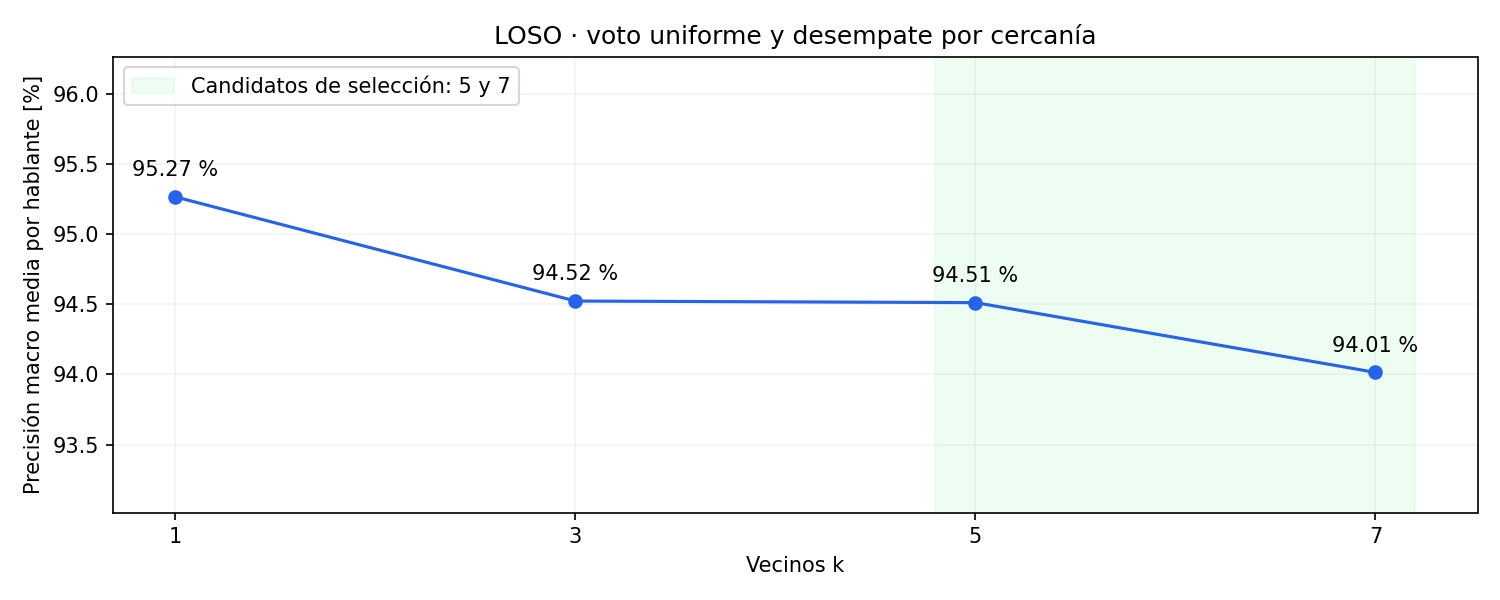

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "documentos/evidencias/07_comandos_voz_precision_v2/precision_k.png"), width=1000))

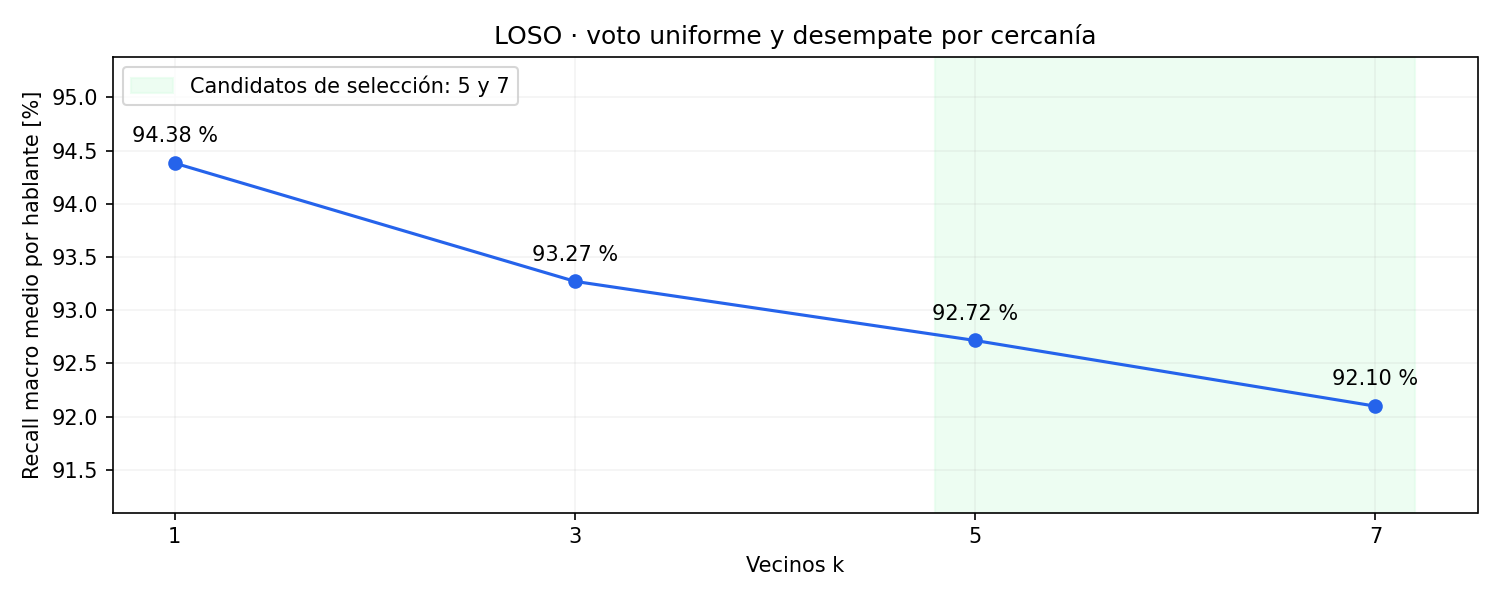

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "documentos/evidencias/07_comandos_voz_precision_v2/recall_k.png"), width=1000))

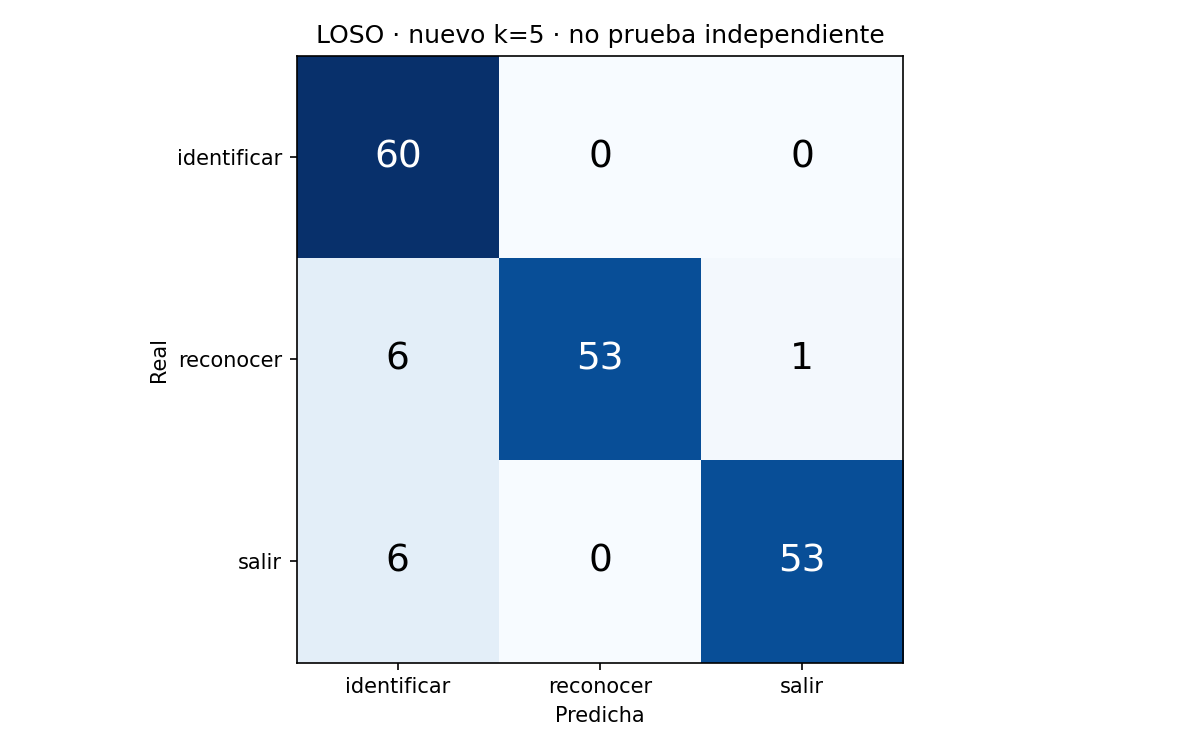

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "documentos/evidencias/07_comandos_voz_precision_v2/confusion_k5.png"), width=1000))